In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import polars as pl

In [3]:
ocv = {
    "gitt": pl.read_csv("data/gitt_ocv.csv"),
    "ici": pl.read_csv("data/ici_ocv.csv").filter(
        pl.col("File / 1").str.contains("-000-ici", strict=False)
    ),
}

ecm = {
    "gitt": pl.read_csv("data/gitt_ecm.csv"),
    "ici": pl.read_csv("data/ici_ecm.csv").filter(
        pl.col("File / 1").str.contains("-001-ici", strict=False)
    ),
}

results = {
    #     pl.col("File / 1").str.contains("-001-ici", strict=False)
    # ),
    "gitt": pl.read_csv("data/gitt_results.csv"),
    "ici": pl.read_csv("data/ici_results.csv"),  # .filter(
}

['DigiBatt-BAK-5000-N21700CG-035-REF-000-ici', 'DigiBatt-BAK-5000-N21700CG-034-REF-000-ici', 'DigiBatt-BAK-5000-N21700CG-029-REF-000-ici']


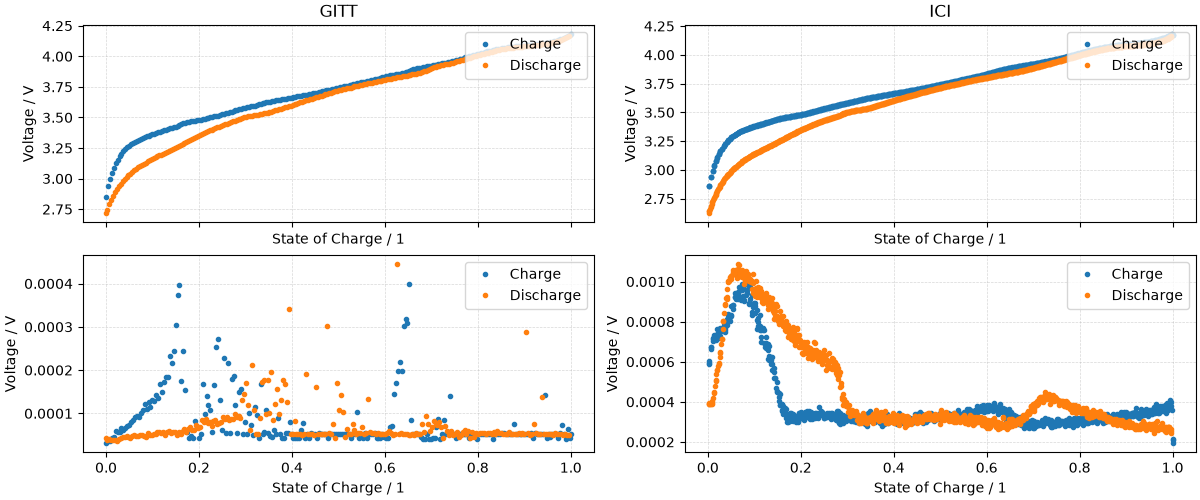

In [4]:
fig, axs = plt.subplots(
    2, 2, figsize=(12, 5), constrained_layout=True, sharex=True, sharey=False
)
for ax in axs.ravel():
    ax.set_xlabel("State of Charge / 1")
    ax.set_ylabel("Voltage / V")
    ax.grid(True, which="both", ls="--", lw=0.5, alpha=0.5)


print(ocv["ici"].select("File / 1").unique().to_series().to_list())
for i, (name, df) in enumerate(ocv.items()):
    axs[0, i].set_title(name.upper())
    for d in df.partition_by("Direction / 1"):
        axs[0, i].plot(
            d.select("State of Charge / 1").to_series(),
            d.select("Open-circuit voltage / V").to_series(),
            marker=".",
            ls="none",
            label=d.select("Direction / 1").unique().item(),
        )
        axs[1, i].plot(
            d.select("State of Charge / 1").to_series(),
            d.select("Open-circuit voltage stdev / V").to_series(),
            marker=".",
            ls="none",
            label=d.select("Direction / 1").unique().item(),
        )
for ax in axs.ravel():
    ax.legend(loc="upper right")
fig.savefig("ocv.png", dpi=300)

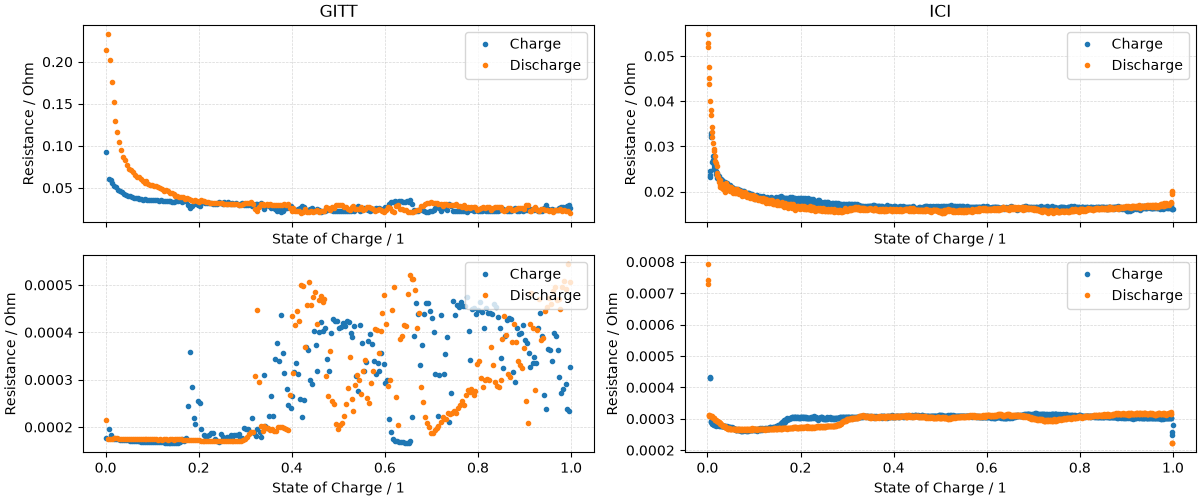

In [11]:
fig, axs = plt.subplots(
    2, 2, figsize=(12, 5), constrained_layout=True, sharex=True, sharey=False
)
# axs[0, 0].sharey(axs[0, 1])
# axs[1, 0].sharey(axs[1, 1])
for ax in axs.ravel():
    ax.set_xlabel("State of Charge / 1")
    ax.set_ylabel("Resistance / Ohm")
    ax.grid(True, which="both", ls="--", lw=0.5, alpha=0.5)


for i, (name, df) in enumerate(ecm.items()):
    axs[0, i].set_title(name.upper())
    for d in df.partition_by("Direction / 1"):
        axs[0, i].plot(
            d.select("State of Charge / 1").to_series(),
            d.select("R0 / Ohm").to_series(),
            marker=".",
            ls="none",
            label=d.select("Direction / 1").unique().item(),
        )
        axs[1, i].plot(
            d.select("State of Charge / 1").to_series(),
            d.select("R0 stdev / Ohm").to_series(),
            marker=".",
            ls="none",
            label=d.select("Direction / 1").unique().item(),
        )
for ax in axs.ravel():
    ax.legend(loc="upper right")
fig.savefig("R0.png", dpi=300)

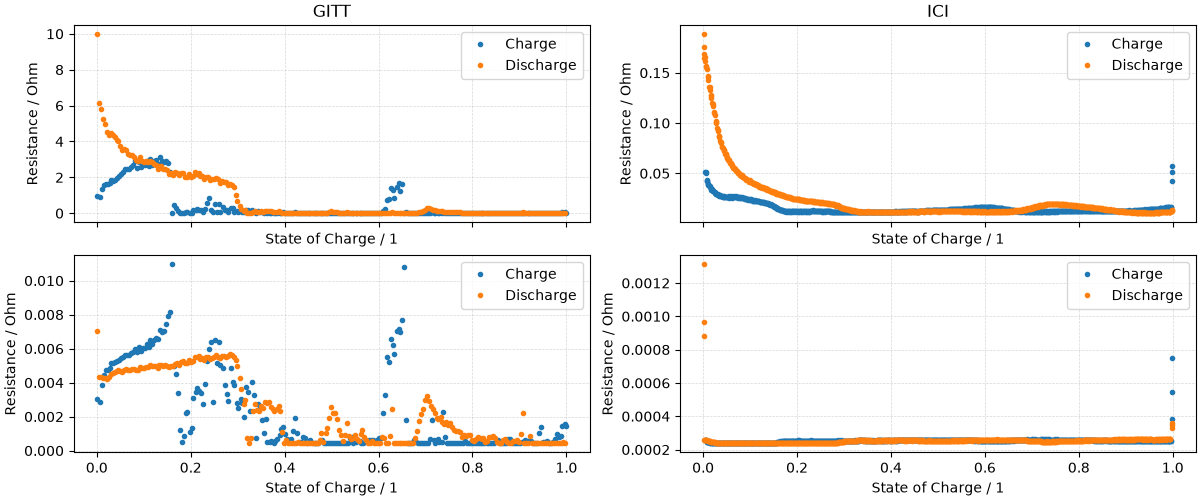

In [12]:
fig, axs = plt.subplots(
    2, 2, figsize=(12, 5), constrained_layout=True, sharex=True, sharey=False
)
# axs[0, 0].sharey(axs[0, 1])
# axs[1, 0].sharey(axs[1, 1])
for ax in axs.ravel():
    ax.set_xlabel("State of Charge / 1")
    ax.set_ylabel("Resistance / Ohm")
    ax.grid(True, which="both", ls="--", lw=0.5, alpha=0.5)


for i, (name, df) in enumerate(ecm.items()):
    axs[0, i].set_title(name.upper())
    for d in df.partition_by("Direction / 1"):
        axs[0, i].plot(
            d.select("State of Charge / 1").to_series(),
            d.select("R1 / Ohm").to_series(),
            marker=".",
            ls="none",
            label=d.select("Direction / 1").unique().item(),
        )
        axs[1, i].plot(
            d.select("State of Charge / 1").to_series(),
            d.select("R1 stdev / Ohm").to_series(),
            marker=".",
            ls="none",
            label=d.select("Direction / 1").unique().item(),
        )
for ax in axs.ravel():
    ax.legend(loc="upper right")
fig.savefig("R1.png", dpi=300)

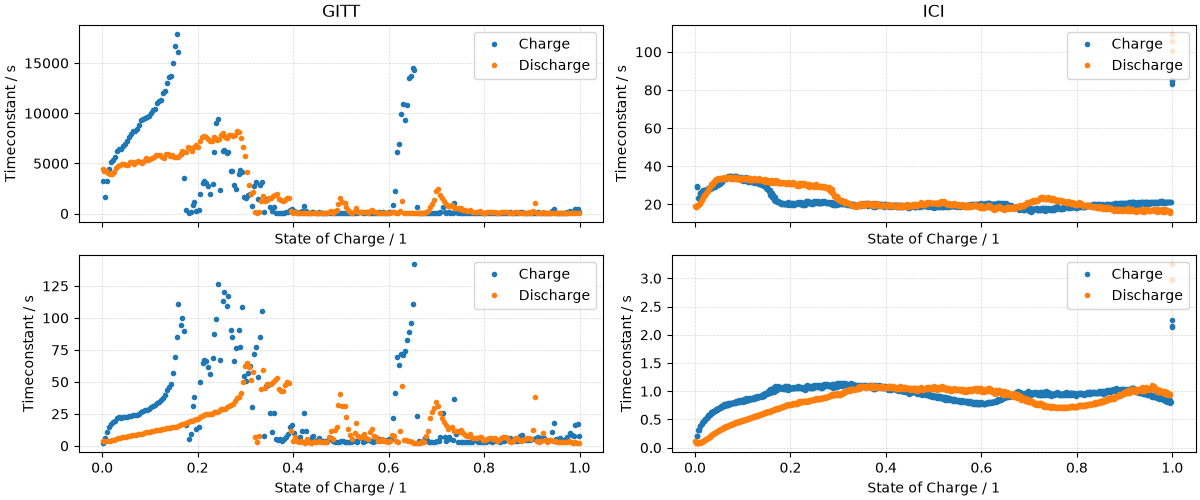

In [13]:
fig, axs = plt.subplots(
    2, 2, figsize=(12, 5), constrained_layout=True, sharex=True, sharey=False
)
# axs[0, 0].sharey(axs[0, 1])
# axs[1, 0].sharey(axs[1, 1])
for ax in axs.ravel():
    ax.set_xlabel("State of Charge / 1")
    ax.set_ylabel("Timeconstant / s")
    ax.grid(True, which="both", ls="--", lw=0.5, alpha=0.5)


for i, (name, df) in enumerate(ecm.items()):
    axs[0, i].set_title(name.upper())
    for d in df.partition_by("Direction / 1"):
        axs[0, i].plot(
            d.select("State of Charge / 1").to_series(),
            d.select("Tau1 / s").to_series(),
            marker=".",
            ls="none",
            label=d.select("Direction / 1").unique().item(),
        )
        axs[1, i].plot(
            d.select("State of Charge / 1").to_series(),
            d.select("Tau1 stdev / s").to_series(),
            marker=".",
            ls="none",
            label=d.select("Direction / 1").unique().item(),
        )
for ax in axs.ravel():
    ax.legend(loc="upper right")    
fig.savefig("Tau1.png", dpi=300)

C:\Users\KristianFredrikKlepp\AppData\Local\Temp\ipykernel_43208\1301173560.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc="upper right")


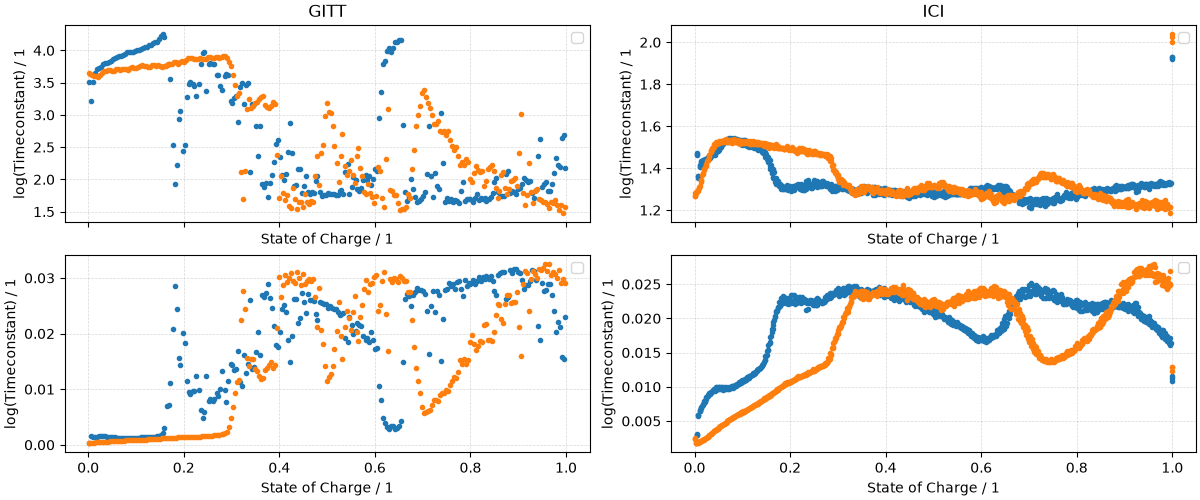

In [9]:
fig, axs = plt.subplots(
    2, 2, figsize=(12, 5), constrained_layout=True, sharex=True, sharey=False
)
# axs[0, 0].sharey(axs[0, 1])
# axs[1, 0].sharey(axs[1, 1])
for ax in axs.ravel():
    ax.set_xlabel("State of Charge / 1")
    ax.set_ylabel("log(Timeconstant) / 1")
    ax.grid(True, which="both", ls="--", lw=0.5, alpha=0.5)


for i, (name, df) in enumerate(ecm.items()):
    axs[0, i].set_title(name.upper())
    for d in df.partition_by("Direction / 1"):
        axs[0, i].plot(
            d.select("State of Charge / 1").to_series(),
            d.select("Log Tau1 / 1").to_series(),
            marker=".",
            ls="none",
        )
        axs[1, i].plot(
            d.select("State of Charge / 1").to_series(),
            d.select("Log Tau1 stdev / 1").to_series(),
            marker=".",
            ls="none",
        )
    for ax in axs.ravel():
        ax.legend(loc="upper right")

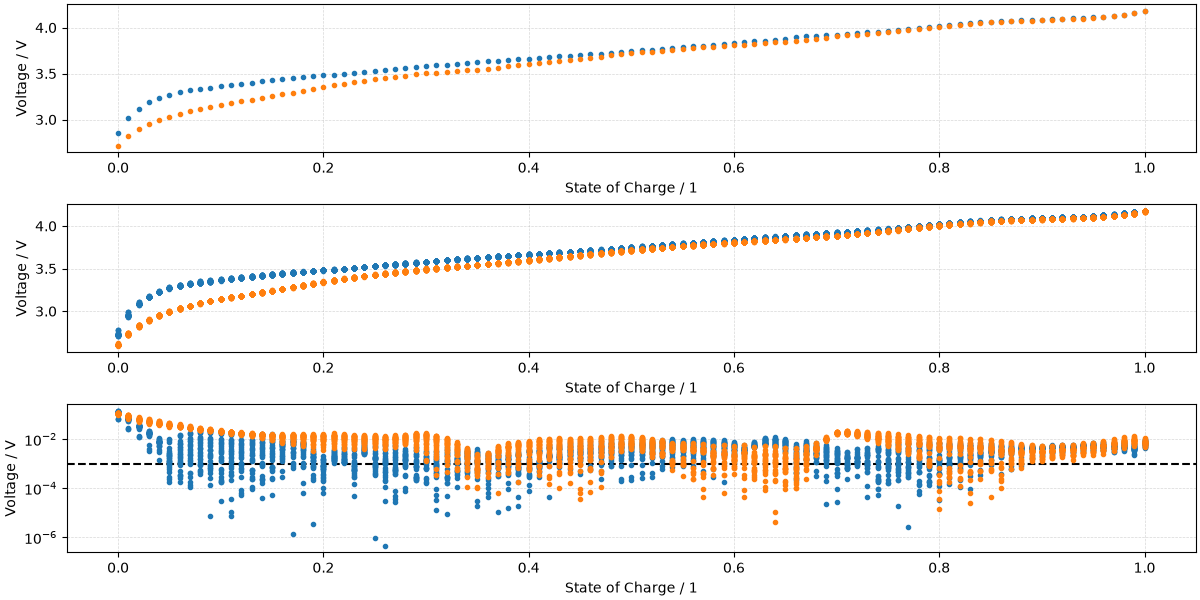

In [12]:
fig, axs = plt.subplots(3, 1, figsize=(12, 6), constrained_layout=True)
for ax in axs.ravel():
    ax.set_xlabel("State of Charge / 1")
    ax.set_ylabel("Voltage / V")
    ax.grid(True, which="both", ls="--", lw=0.5, alpha=0.5)
axs[2].axhline(1e-3, color="k", ls="--")
for d in ["Charge", "Discharge"]:
    df_gitt = results["gitt"].filter(pl.col("Direction / 1") == d)
    (line,) = axs[0].plot(
        df_gitt.select("State of Charge / 1").to_series(),
        df_gitt.select("Open-circuit voltage / V").to_series(),
        marker=".",
        ls="none",
        label=f"GITT {d}",
    )
    for file in results["ici"].select("File / 1").unique().to_series().to_list():
        df_ici = (
            results["ici"]
            .filter(pl.col("File / 1") == file)
            .filter(pl.col("Direction / 1") == d)
        )

        axs[1].plot(
            df_ici.select("State of Charge / 1").to_series(),
            df_ici.select("Open-circuit voltage / V").to_series(),
            color=line.get_color(),
            marker=".",
            ls="none",
            label=f"{file} {d}",
        )
        (line_,) = axs[2].semilogy(
            df_ici.select("State of Charge / 1").to_series(),
            np.abs(
                df_ici.select("Open-circuit voltage / V").to_series()
                - df_gitt.select("Open-circuit voltage / V").to_series()
            ),
            color=line.get_color(),
            marker=".",
            ls="none",
            label=f"{file} {d}",
        )
        color = line_.get_color()


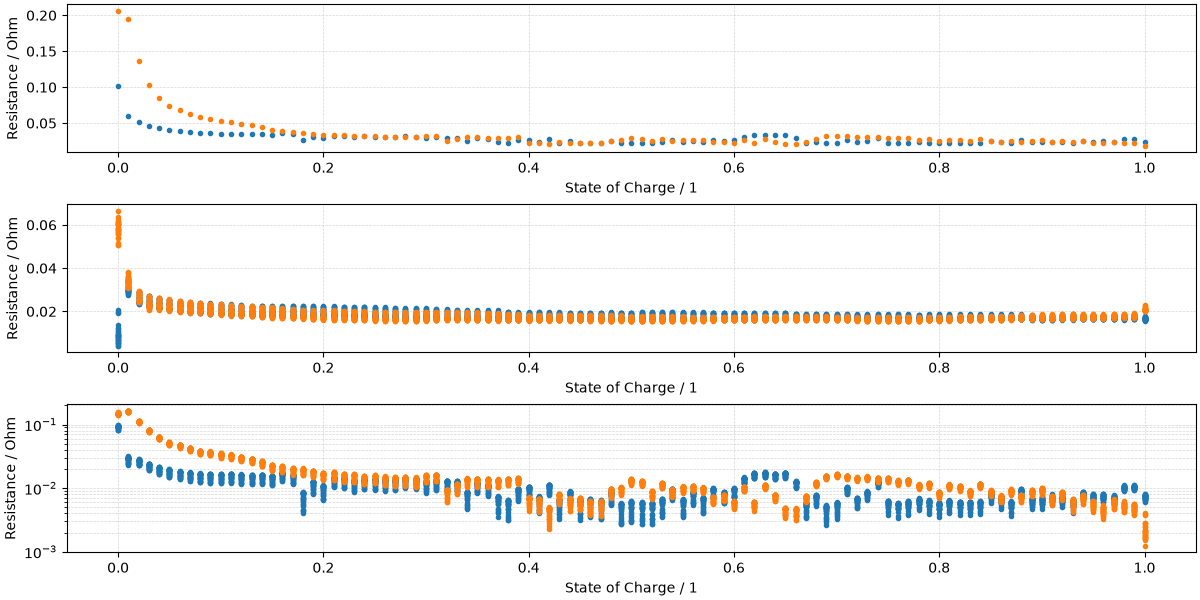

In [13]:
fig, axs = plt.subplots(3, 1, figsize=(12, 6), constrained_layout=True)
for ax in axs.ravel():
    ax.set_xlabel("State of Charge / 1")
    ax.set_ylabel("Resistance / Ohm")
    ax.grid(True, which="both", ls="--", lw=0.5, alpha=0.5)
for d in ["Charge", "Discharge"]:
    df_gitt = results["gitt"].filter(pl.col("Direction / 1") == d)
    (line,) = axs[0].plot(
        df_gitt.select("State of Charge / 1").to_series(),
        df_gitt.select("R0 / Ohm").to_series(),
        marker=".",
        ls="none",
        label=f"GITT {d}",
    )
    for file in results["ici"].select("File / 1").unique().to_series().to_list():
        df_ici = (
            results["ici"]
            .filter(pl.col("File / 1") == file)
            .filter(pl.col("Direction / 1") == d)
        )

        axs[1].plot(
            df_ici.select("State of Charge / 1").to_series(),
            df_ici.select("R0 / Ohm").to_series(),
            color=line.get_color(),
            marker=".",
            ls="none",
            label=f"{file} {d}",
        )
        (line_,) = axs[2].semilogy(
            df_ici.select("State of Charge / 1").to_series(),
            np.abs(
                df_ici.select("R0 / Ohm").to_series()
                - df_gitt.select("R0 / Ohm").to_series()
            ),
            color=line.get_color(),
            marker=".",
            ls="none",
            label=f"{file} {d}",
        )

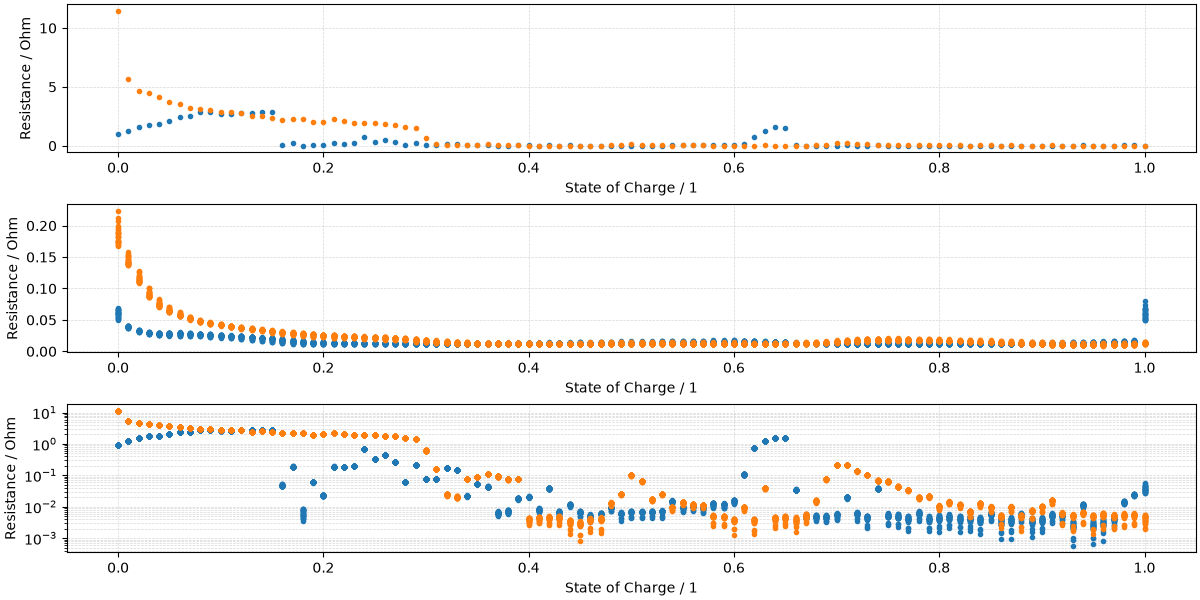

In [14]:
fig, axs = plt.subplots(3, 1, figsize=(12, 6), constrained_layout=True)
for ax in axs.ravel():
    ax.set_xlabel("State of Charge / 1")
    ax.set_ylabel("Resistance / Ohm")
    ax.grid(True, which="both", ls="--", lw=0.5, alpha=0.5)
for d in ["Charge", "Discharge"]:
    df_gitt = results["gitt"].filter(pl.col("Direction / 1") == d)
    (line,) = axs[0].plot(
        df_gitt.select("State of Charge / 1").to_series(),
        df_gitt.select("R1 / Ohm").to_series(),
        marker=".",
        ls="none",
        label=f"GITT {d}",
    )
    for file in results["ici"].select("File / 1").unique().to_series().to_list():
        df_ici = (
            results["ici"]
            .filter(pl.col("File / 1") == file)
            .filter(pl.col("Direction / 1") == d)
        )

        axs[1].plot(
            df_ici.select("State of Charge / 1").to_series(),
            df_ici.select("R1 / Ohm").to_series(),
            color=line.get_color(),
            marker=".",
            ls="none",
            label=f"{file} {d}",
        )
        (line_,) = axs[2].semilogy(
            df_ici.select("State of Charge / 1").to_series(),
            np.abs(
                df_ici.select("R1 / Ohm").to_series()
                - df_gitt.select("R1 / Ohm").to_series()
            ),
            color=line.get_color(),
            marker=".",
            ls="none",
            label=f"{file} {d}",
        )

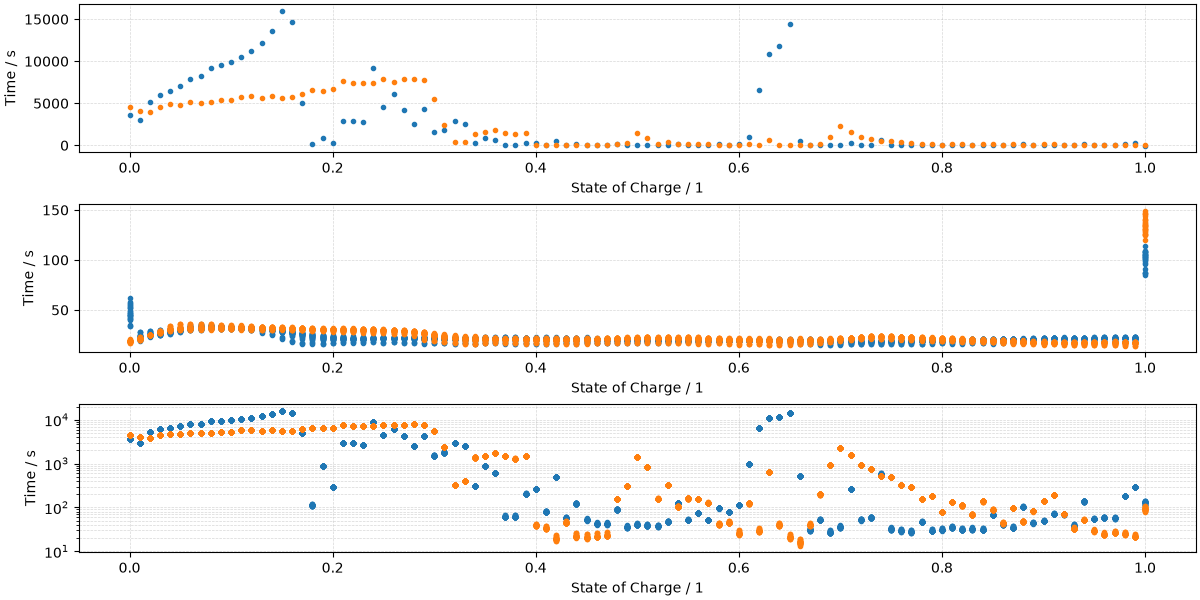

In [156]:
fig, axs = plt.subplots(3, 1, figsize=(12, 6), constrained_layout=True)
for ax in axs.ravel():
    ax.set_xlabel("State of Charge / 1")
    ax.set_ylabel("Time / s")
    ax.grid(True, which="both", ls="--", lw=0.5, alpha=0.5)
for d in ["Charge", "Discharge"]:
    df_gitt = results["gitt"].filter(pl.col("Direction / 1") == d)
    (line,) = axs[0].plot(
        df_gitt.select("State of Charge / 1").to_series(),
        df_gitt.select("Tau1 / s").to_series(),
        marker=".",
        ls="none",
        label=f"GITT {d}",
    )
    for file in results["ici"].select("File / 1").unique().to_series().to_list():
        df_ici = (
            results["ici"]
            .filter(pl.col("File / 1") == file)
            .filter(pl.col("Direction / 1") == d)
        )

        axs[1].plot(
            df_ici.select("State of Charge / 1").to_series(),
            df_ici.select("Tau1 / s").to_series(),
            color=line.get_color(),
            marker=".",
            ls="none",
            label=f"{file} {d}",
        )
        (line_,) = axs[2].semilogy(
            df_ici.select("State of Charge / 1").to_series(),
            np.abs(
                df_ici.select("Tau1 / s").to_series()
                - df_gitt.select("Tau1 / s").to_series()
            ),
            color=line.get_color(),
            marker=".",
            ls="none",
            label=f"{file} {d}",
        )